# Volcano Plots & PCA — Spaceflight RNA-seq (Publication Figures, 300 DPI)

This notebook generates:
- **3 volcano plots**, one per DEG comparison (Flight vs Ground, Post-Flight vs Ground, Post-Flight vs Flight)
- **1 PCA plot** from the normalized counts + metadata, with samples labeled by their full GSM ID

**Significance rule used for volcano plots:**
- **Upregulated**: log2(Fold Change) > 2 **and** p-value < 0.05
- **Downregulated**: log2(Fold Change) < -2 **and** p-value < 0.05
- Everything else: Not significant

All figures are saved at 300 DPI as PNG (for direct use) and PDF (vector, for further editing).

**Running this in Google Colab?** Upload **all five** input files to the Colab session
(`Flight_vs_Ground.txt`, `Post_Flight_vs_Ground.txt`, `Post_Flight_vs_Flight.txt`,
`Normalized_Counts_GLbulkRNAseq.csv`, `metadata.txt`) — Colab's `/content` folder is
empty at the start of every session, so missing any one of them will raise a
`FileNotFoundError` later in the notebook. The path-detection cell below points
`INPUT_DIR`/`OUTPUT_DIR` at `/content` automatically when it detects a Colab
environment; otherwise it uses `/mnt/user-data/uploads` and `/mnt/user-data/outputs`.

## 1. Install & import dependencies

In [1]:
# Install adjustText first (before importing it) so it's available for the
# rest of the notebook in one pass — no need to re-run the import cell after.
import importlib
if importlib.util.find_spec("adjustText") is None:
    import sys
    !{sys.executable} -m pip install -q adjustText

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

%matplotlib inline

try:
    from adjustText import adjust_text
    HAVE_ADJUSTTEXT = True
except ImportError:
    HAVE_ADJUSTTEXT = False
    print("adjustText still not available — labels will not be auto-spaced. "
          "Re-run the cell above, then re-run this cell.")

## 2. Configuration

Edit paths and thresholds here.

Expected input files:
- `Flight_vs_Ground.txt`, `Post_Flight_vs_Ground.txt`, `Post_Flight_vs_Flight.txt`
  (tab-separated: `ENSEMBL`, `SYMBOL`, `Log2fc_(...)`, `P.value_(...)`)
- `Normalized_Counts_GLbulkRNAseq.csv` (genes x samples, first column = gene ID)
- `metadata.txt` (tab-separated: `sample_id`, `sample_type`)

In [3]:
import os

# Auto-detect Colab vs. this environment so the same notebook runs in either
# without editing paths by hand.
IN_COLAB = os.path.exists("/content") and "google.colab" in str(get_ipython())
if IN_COLAB:
    INPUT_DIR = "/content"
    OUTPUT_DIR = "/content"
else:
    INPUT_DIR = "/mnt/user-data/uploads"
    OUTPUT_DIR = "/mnt/user-data/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# DEG comparison files: filename, log2FC column, p-value column, plot title, output basename
COMPARISONS = [
    {
        "file": "Flight_vs_Ground.txt",
        "lfc_col": "Log2fc_(Flight vs Ground)",
        "pval_col": "P.value_(Flight vs Ground)",
        "title": "Flight vs Ground",
        "out": "volcano_Flight_vs_Ground",
    },
    {
        "file": "Post_Flight_vs_Ground.txt",
        "lfc_col": "Log2fc_(Post_Flight vs Ground)",
        "pval_col": "P.value_(Post_Flight vs Ground)",
        "title": "Post-Flight vs Ground",
        "out": "volcano_PostFlight_vs_Ground",
    },
    {
        "file": "Post_Flight_vs_Flight.txt",
        "lfc_col": "Log2fc_(Post_Flight vs Flight)",
        "pval_col": "P.value_(Post_Flight vs Flight)",
        "title": "Post-Flight vs Flight",
        "out": "volcano_PostFlight_vs_Flight",
    },
]
COUNTS_FILE = "Normalized_Counts_GLbulkRNAseq.csv"
METADATA_FILE = "metadata.txt"

# --- Significance thresholds ---
# Upregulated:   log2FC > LFC_THRESHOLD   and p-value < PVAL_THRESHOLD
# Downregulated: log2FC < -LFC_THRESHOLD  and p-value < PVAL_THRESHOLD
LFC_THRESHOLD = 2.0
PVAL_THRESHOLD = 0.05
TOP_N_LABELS = 15     # number of top (most significant) genes to label per volcano plot
DPI = 300

# Color palette (colorblind-friendly)
COLOR_UP = "#D6604D"     # red
COLOR_DOWN = "#4393C3"   # blue
COLOR_NS = "#B0B0B0"     # grey

# Fail fast with a clear message if a required file is missing, rather than
# a raw FileNotFoundError partway through plotting.
required_files = [c["file"] for c in COMPARISONS] + [COUNTS_FILE, METADATA_FILE]
missing = [f for f in required_files if not os.path.exists(os.path.join(INPUT_DIR, f))]
if missing:
    raise FileNotFoundError(
        f"Missing input file(s) in {INPUT_DIR}: {missing}. "
        f"Upload all required files there before running the rest of the notebook."
    )
print(f"All input files found in {INPUT_DIR}")

All input files found in /mnt/user-data/uploads


## 3. Publication-style plot settings (big, bold, clear)

In [4]:
plt.rcParams.update({
    "figure.dpi": DPI,
    "savefig.dpi": DPI,
    "font.size": 16,
    "font.weight": "bold",
    "axes.titlesize": 20,
    "axes.titleweight": "bold",
    "axes.labelsize": 18,
    "axes.labelweight": "bold",
    "axes.linewidth": 2.0,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "xtick.major.width": 2.0,
    "ytick.major.width": 2.0,
    "legend.fontsize": 13,
    "legend.title_fontsize": 14,
    "font.family": "DejaVu Sans",
    "savefig.bbox": "tight",
    "svg.fonttype": "none",
})

## 4. Volcano plot function

- Classifies genes as **Up** (log2FC > threshold & p < 0.05), **Down** (log2FC < -threshold & p < 0.05), or **Not significant**.
- X-axis is capped near the 99.5th percentile of |log2FC| so a handful of extreme, low-confidence fold changes (common for near-zero-count genes) don't compress the rest of the plot.
- Labels the top N most statistically significant Up/Down genes, auto-spaced with `adjustText` to avoid overlap.

In [5]:
def make_volcano(filepath, lfc_col, pval_col, title, out_basename):
    df = pd.read_csv(filepath, sep="\t")

    # fail with a clear message if the expected columns aren't present,
    # rather than a cryptic KeyError deep inside plotting
    missing_cols = [c for c in (lfc_col, pval_col) if c not in df.columns]
    if missing_cols:
        raise ValueError(
            f"{filepath}: missing expected column(s) {missing_cols}. "
            f"Available columns: {list(df.columns)}"
        )

    df = df.dropna(subset=[lfc_col, pval_col]).copy()

    # avoid log(0) issues
    min_nonzero_p = df.loc[df[pval_col] > 0, pval_col].min()
    df[pval_col] = df[pval_col].replace(0, min_nonzero_p / 10)
    df["neglog10p"] = -np.log10(df[pval_col])

    # classify genes
    def classify(row):
        if row[pval_col] < PVAL_THRESHOLD and row[lfc_col] > LFC_THRESHOLD:
            return "Up"
        elif row[pval_col] < PVAL_THRESHOLD and row[lfc_col] < -LFC_THRESHOLD:
            return "Down"
        else:
            return "NS"

    df["status"] = df.apply(classify, axis=1)
    n_up = (df["status"] == "Up").sum()
    n_down = (df["status"] == "Down").sum()

    fig, ax = plt.subplots(figsize=(10, 8.5))

    for status, color, zorder in [("NS", COLOR_NS, 1), ("Down", COLOR_DOWN, 2), ("Up", COLOR_UP, 2)]:
        sub = df[df["status"] == status]
        ax.scatter(
            sub[lfc_col], sub["neglog10p"],
            s=22 if status == "NS" else 30,
            c=color, alpha=0.65 if status == "NS" else 0.85,
            linewidths=0, zorder=zorder,
        )

    # threshold guide lines
    ax.axhline(-np.log10(PVAL_THRESHOLD), color="black", linestyle="--", linewidth=1.5, alpha=0.7)
    ax.axvline(LFC_THRESHOLD, color="black", linestyle="--", linewidth=1.5, alpha=0.7)
    ax.axvline(-LFC_THRESHOLD, color="black", linestyle="--", linewidth=1.5, alpha=0.7)

    # x-axis: focus on the bulk of the data (a handful of near-zero-count genes
    # can produce extreme, low-confidence fold changes that would otherwise
    # stretch the axis and empty out the plot)
    xlim = np.percentile(df[lfc_col].abs(), 99.5) * 1.4
    xlim = max(xlim, LFC_THRESHOLD * 3)

    # label top genes: most statistically significant genes among Up/Down,
    # restricted to the visible x-range so labels never land off-canvas
    sig = df[(df["status"] != "NS") & (df[lfc_col].abs() <= xlim)].copy()
    top_genes = sig.sort_values(pval_col, ascending=True).head(TOP_N_LABELS)

    texts = []
    for _, row in top_genes.iterrows():
        label = row["SYMBOL"] if pd.notna(row.get("SYMBOL", np.nan)) else row["ENSEMBL"]
        texts.append(
            ax.text(row[lfc_col], row["neglog10p"], str(label),
                     fontsize=11, fontweight="bold", zorder=5)
        )

    ax.set_xlim(-xlim, xlim)
    ytop = df["neglog10p"].max() * 1.15
    ax.set_ylim(bottom=-ytop * 0.02, top=ytop)

    if texts:
        if HAVE_ADJUSTTEXT:
            adjust_text(
                texts, ax=ax,
                expand_text=(1.2, 1.4), expand_points=(1.2, 1.4),
                force_text=(0.4, 0.6), force_points=(0.3, 0.4),
                arrowprops=dict(arrowstyle="-", color="black", lw=0.8, alpha=0.7),
            )
        # keep every label within the plotted axes, even if adjustText nudged
        # one outside while resolving overlaps; stagger any that land on the
        # same clamped edge so they don't overlap each other
        edge_positions = {}
        for t in texts:
            tx, ty = t.get_position()
            clamped_x = min(max(tx, -xlim * 0.98), xlim * 0.98)
            clamped_y = min(max(ty, 0), ytop * 0.98)
            if (tx, ty) != (clamped_x, clamped_y):
                key = round(clamped_x, 1)
                n = edge_positions.get(key, 0)
                clamped_y = max(0, clamped_y - n * ytop * 0.035)
                edge_positions[key] = n + 1
            t.set_position((clamped_x, clamped_y))

    ax.set_xlabel("log$_2$(Fold Change)")
    ax.set_ylabel("-log$_{10}$(p-value)")
    ax.set_title(title, pad=14)

    legend_elements = [
        Patch(facecolor=COLOR_UP, label=f"Up ({n_up})"),
        Patch(facecolor=COLOR_DOWN, label=f"Down ({n_down})"),
        Patch(facecolor=COLOR_NS, label="Not significant"),
    ]
    leg = ax.legend(handles=legend_elements, loc="upper left", frameon=True,
                     framealpha=1.0, facecolor="white", edgecolor="black")
    leg.set_zorder(10)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(width=2, length=6)

    fig.tight_layout()
    png_path = os.path.join(OUTPUT_DIR, f"{out_basename}.png")
    pdf_path = os.path.join(OUTPUT_DIR, f"{out_basename}.pdf")
    fig.savefig(png_path, dpi=DPI)
    fig.savefig(pdf_path, dpi=DPI)
    plt.show()
    plt.close(fig)
    print(f"Saved: {png_path} ({n_up} up / {n_down} down / {len(df)} total genes)")
    return df

## 5. PCA plot function

- Uses the top 2000 most variable genes (log2-transformed normalized counts), z-scored, then PCA.
- Colors/shapes points by `sample_type` from `metadata.txt`.
- Labels every point with its **full GSM sample ID**, auto-spaced with `adjustText`.

In [6]:
def make_pca(counts_path, metadata_path, out_basename="PCA_plot"):
    counts = pd.read_csv(counts_path, index_col=0)
    meta = pd.read_csv(metadata_path, sep="\t")
    meta = meta.set_index("sample_id")

    # align sample order
    counts = counts[[c for c in counts.columns if c in meta.index]]
    meta = meta.loc[counts.columns]

    # log2 transform (counts are already normalized) + filter to most variable genes
    log_counts = np.log2(counts + 1)
    variances = log_counts.var(axis=1)
    top_var_genes = variances.sort_values(ascending=False).head(2000).index
    mat = log_counts.loc[top_var_genes].T  # samples x genes

    scaled = StandardScaler().fit_transform(mat)
    pca = PCA(n_components=2, random_state=0)
    scores = pca.fit_transform(scaled)
    var_explained = pca.explained_variance_ratio_ * 100

    plot_df = pd.DataFrame(scores, columns=["PC1", "PC2"], index=mat.index)
    plot_df["group"] = meta["sample_type"].values

    groups = list(dict.fromkeys(meta["sample_type"]))  # preserve order of appearance
    palette = {"Flight": "#D6604D", "PostFlight": "#4393C3", "Ground": "#4DAF4A"}
    fallback_colors = ["#D6604D", "#4393C3", "#4DAF4A", "#984EA3", "#FF7F00"]
    for i, g in enumerate(groups):
        if g not in palette:
            palette[g] = fallback_colors[i % len(fallback_colors)]

    markers = {"Flight": "o", "PostFlight": "s", "Ground": "^"}
    fallback_markers = ["o", "s", "^", "D", "P"]
    for i, g in enumerate(groups):
        if g not in markers:
            markers[g] = fallback_markers[i % len(fallback_markers)]

    fig, ax = plt.subplots(figsize=(9, 8))

    for g in groups:
        sub = plot_df[plot_df["group"] == g]
        ax.scatter(
            sub["PC1"], sub["PC2"],
            s=220, c=palette[g], marker=markers[g],
            edgecolors="black", linewidths=1.8,
            label=g, alpha=0.9, zorder=3,
        )

    # label each sample point with its full GSM sample ID (de-overlapped)
    label_texts = []
    for sample_id, row in plot_df.iterrows():
        label_texts.append(
            ax.text(row["PC1"], row["PC2"], str(sample_id),
                     fontsize=9, fontweight="normal", alpha=0.75, zorder=4)
        )
    if HAVE_ADJUSTTEXT:
        adjust_text(
            label_texts, ax=ax,
            expand_text=(1.2, 1.4), expand_points=(1.4, 1.6),
            arrowprops=dict(arrowstyle="-", color="grey", lw=0.7, alpha=0.6),
        )

    ax.set_xlabel(f"PC1 ({var_explained[0]:.1f}% variance)")
    ax.set_ylabel(f"PC2 ({var_explained[1]:.1f}% variance)")
    ax.set_title("PCA of Normalized RNA-seq Counts", pad=14)
    ax.axhline(0, color="grey", linewidth=1, linestyle=":", alpha=0.6)
    ax.axvline(0, color="grey", linewidth=1, linestyle=":", alpha=0.6)

    ax.legend(title="Sample Type", loc="best", frameon=True,
              framealpha=0.9, edgecolor="black")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(width=2, length=6)

    fig.tight_layout()
    png_path = os.path.join(OUTPUT_DIR, f"{out_basename}.png")
    pdf_path = os.path.join(OUTPUT_DIR, f"{out_basename}.pdf")
    fig.savefig(png_path, dpi=DPI)
    fig.savefig(pdf_path, dpi=DPI)
    plt.show()
    plt.close(fig)
    print(f"Saved: {png_path}")
    return plot_df

## 6. Generate the volcano plots (one per comparison)

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


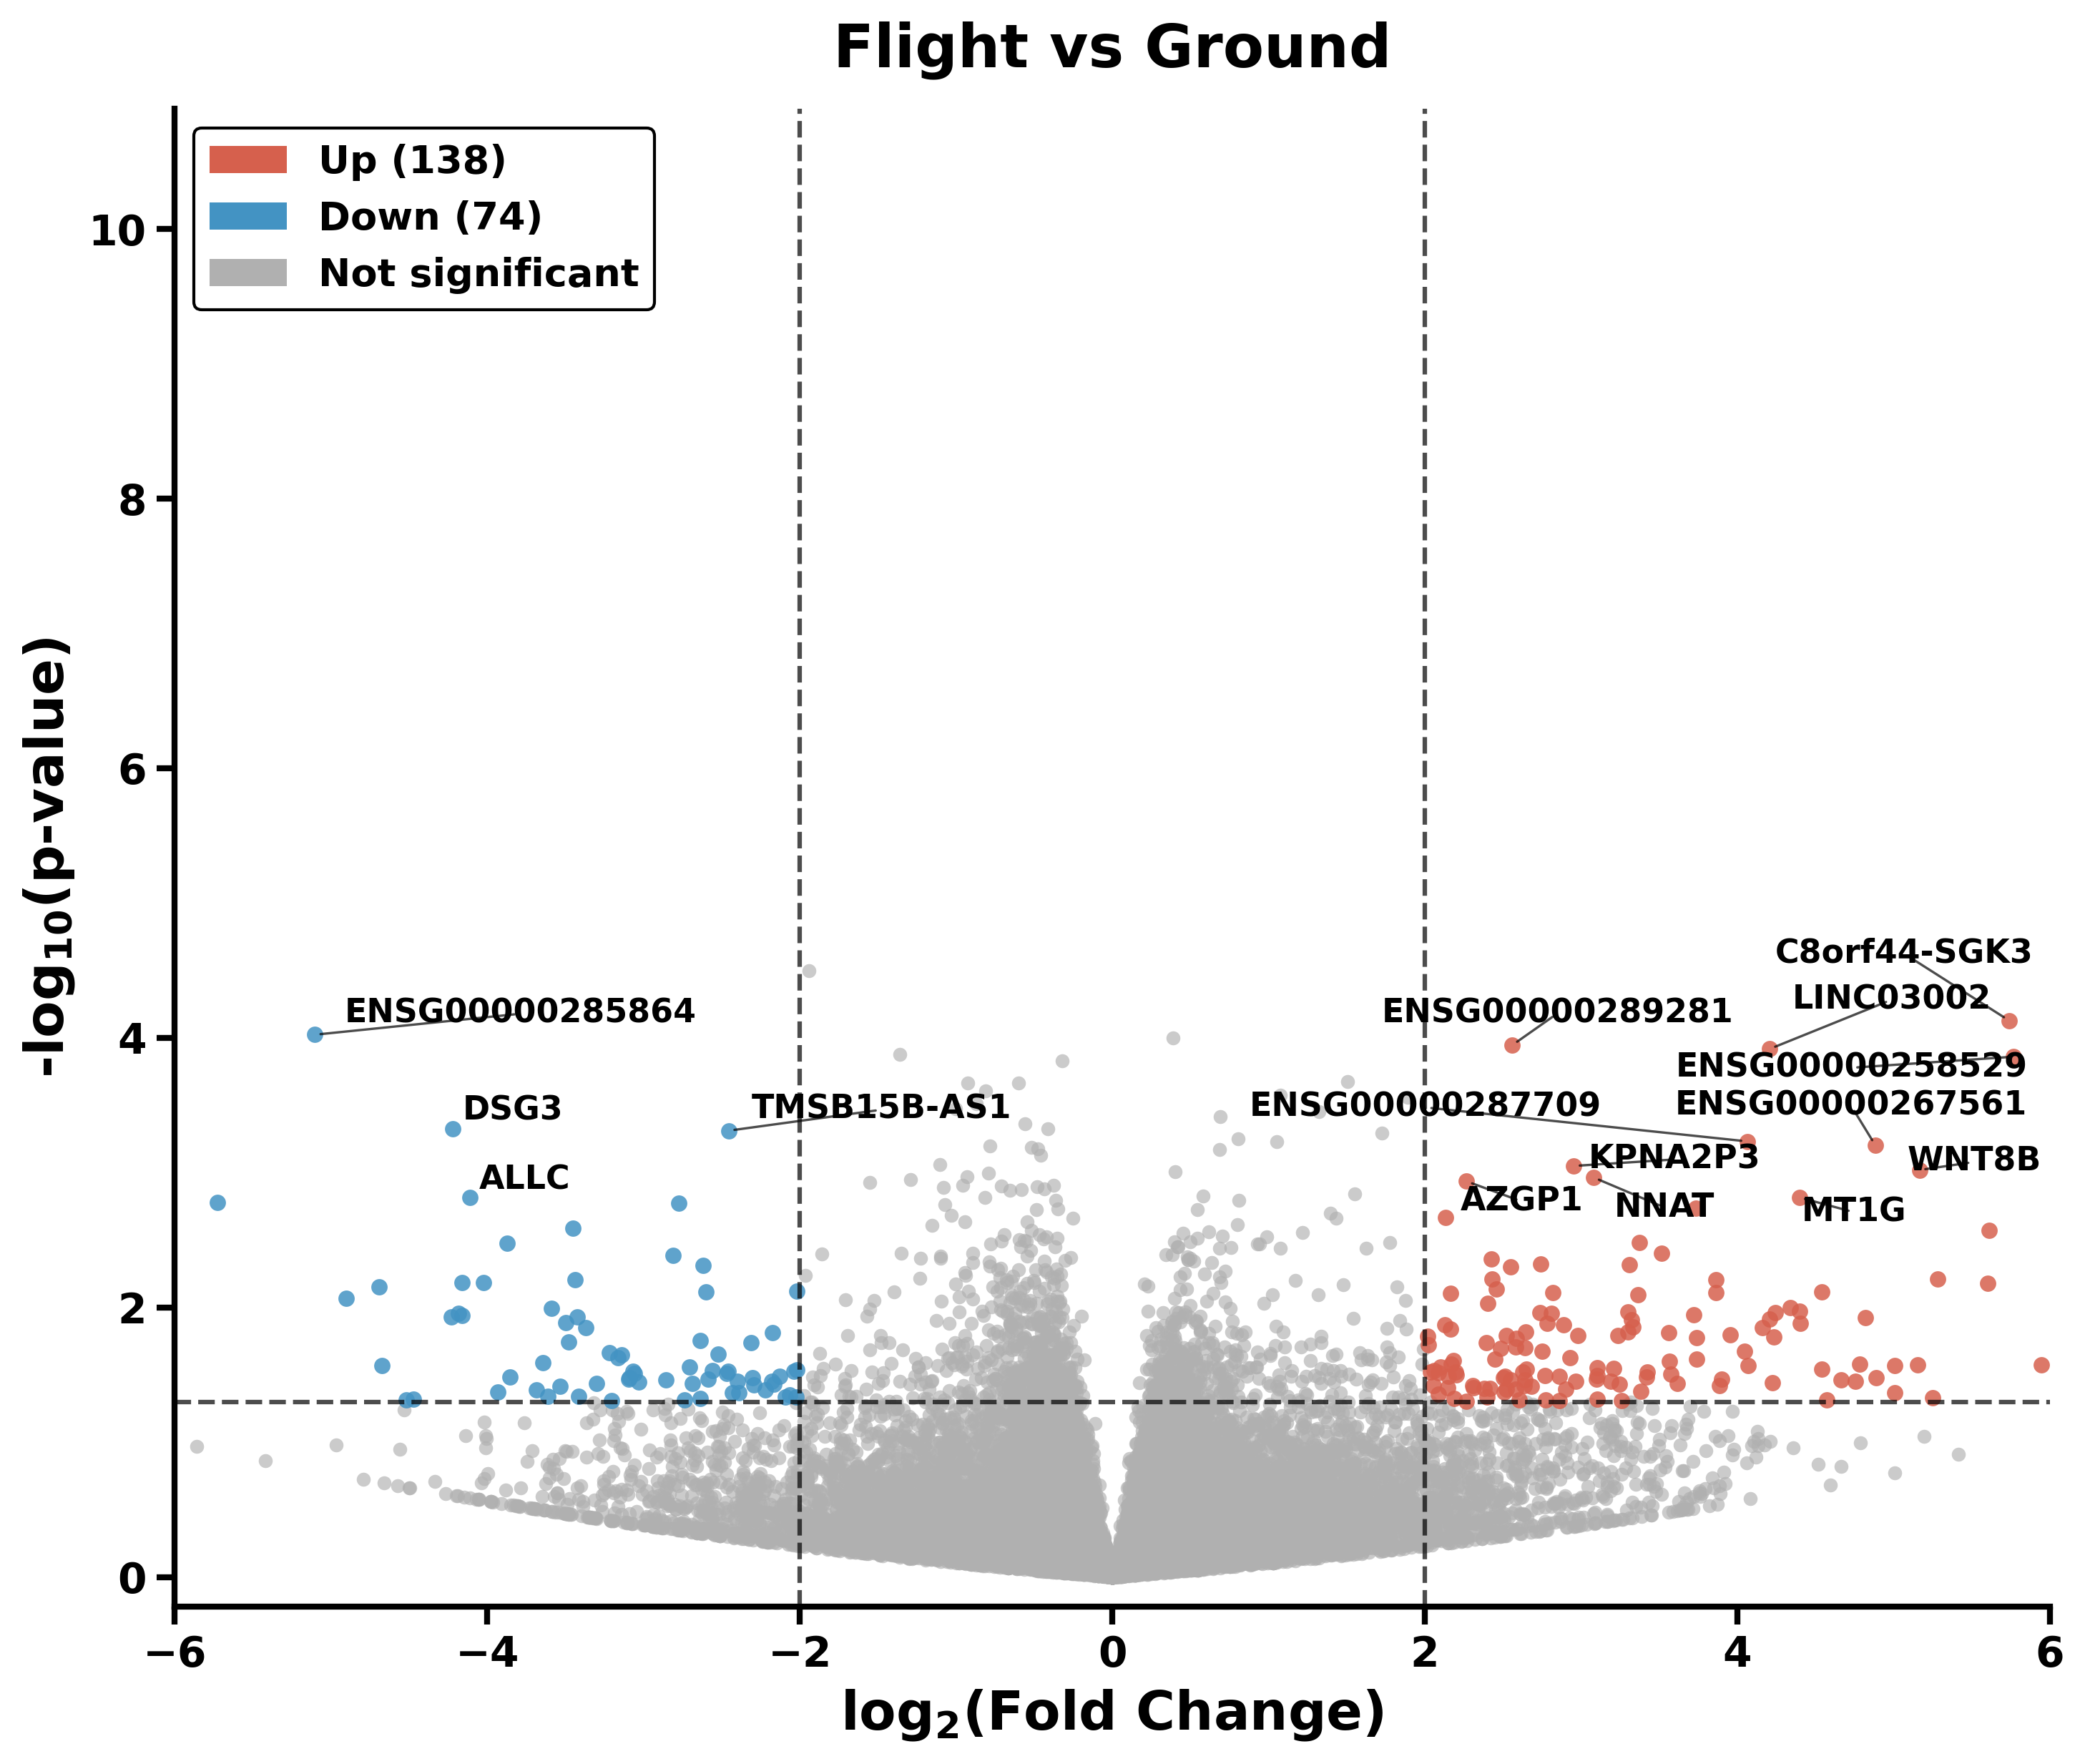

Saved: /mnt/user-data/outputs/volcano_Flight_vs_Ground.png (138 up / 74 down / 26935 total genes)


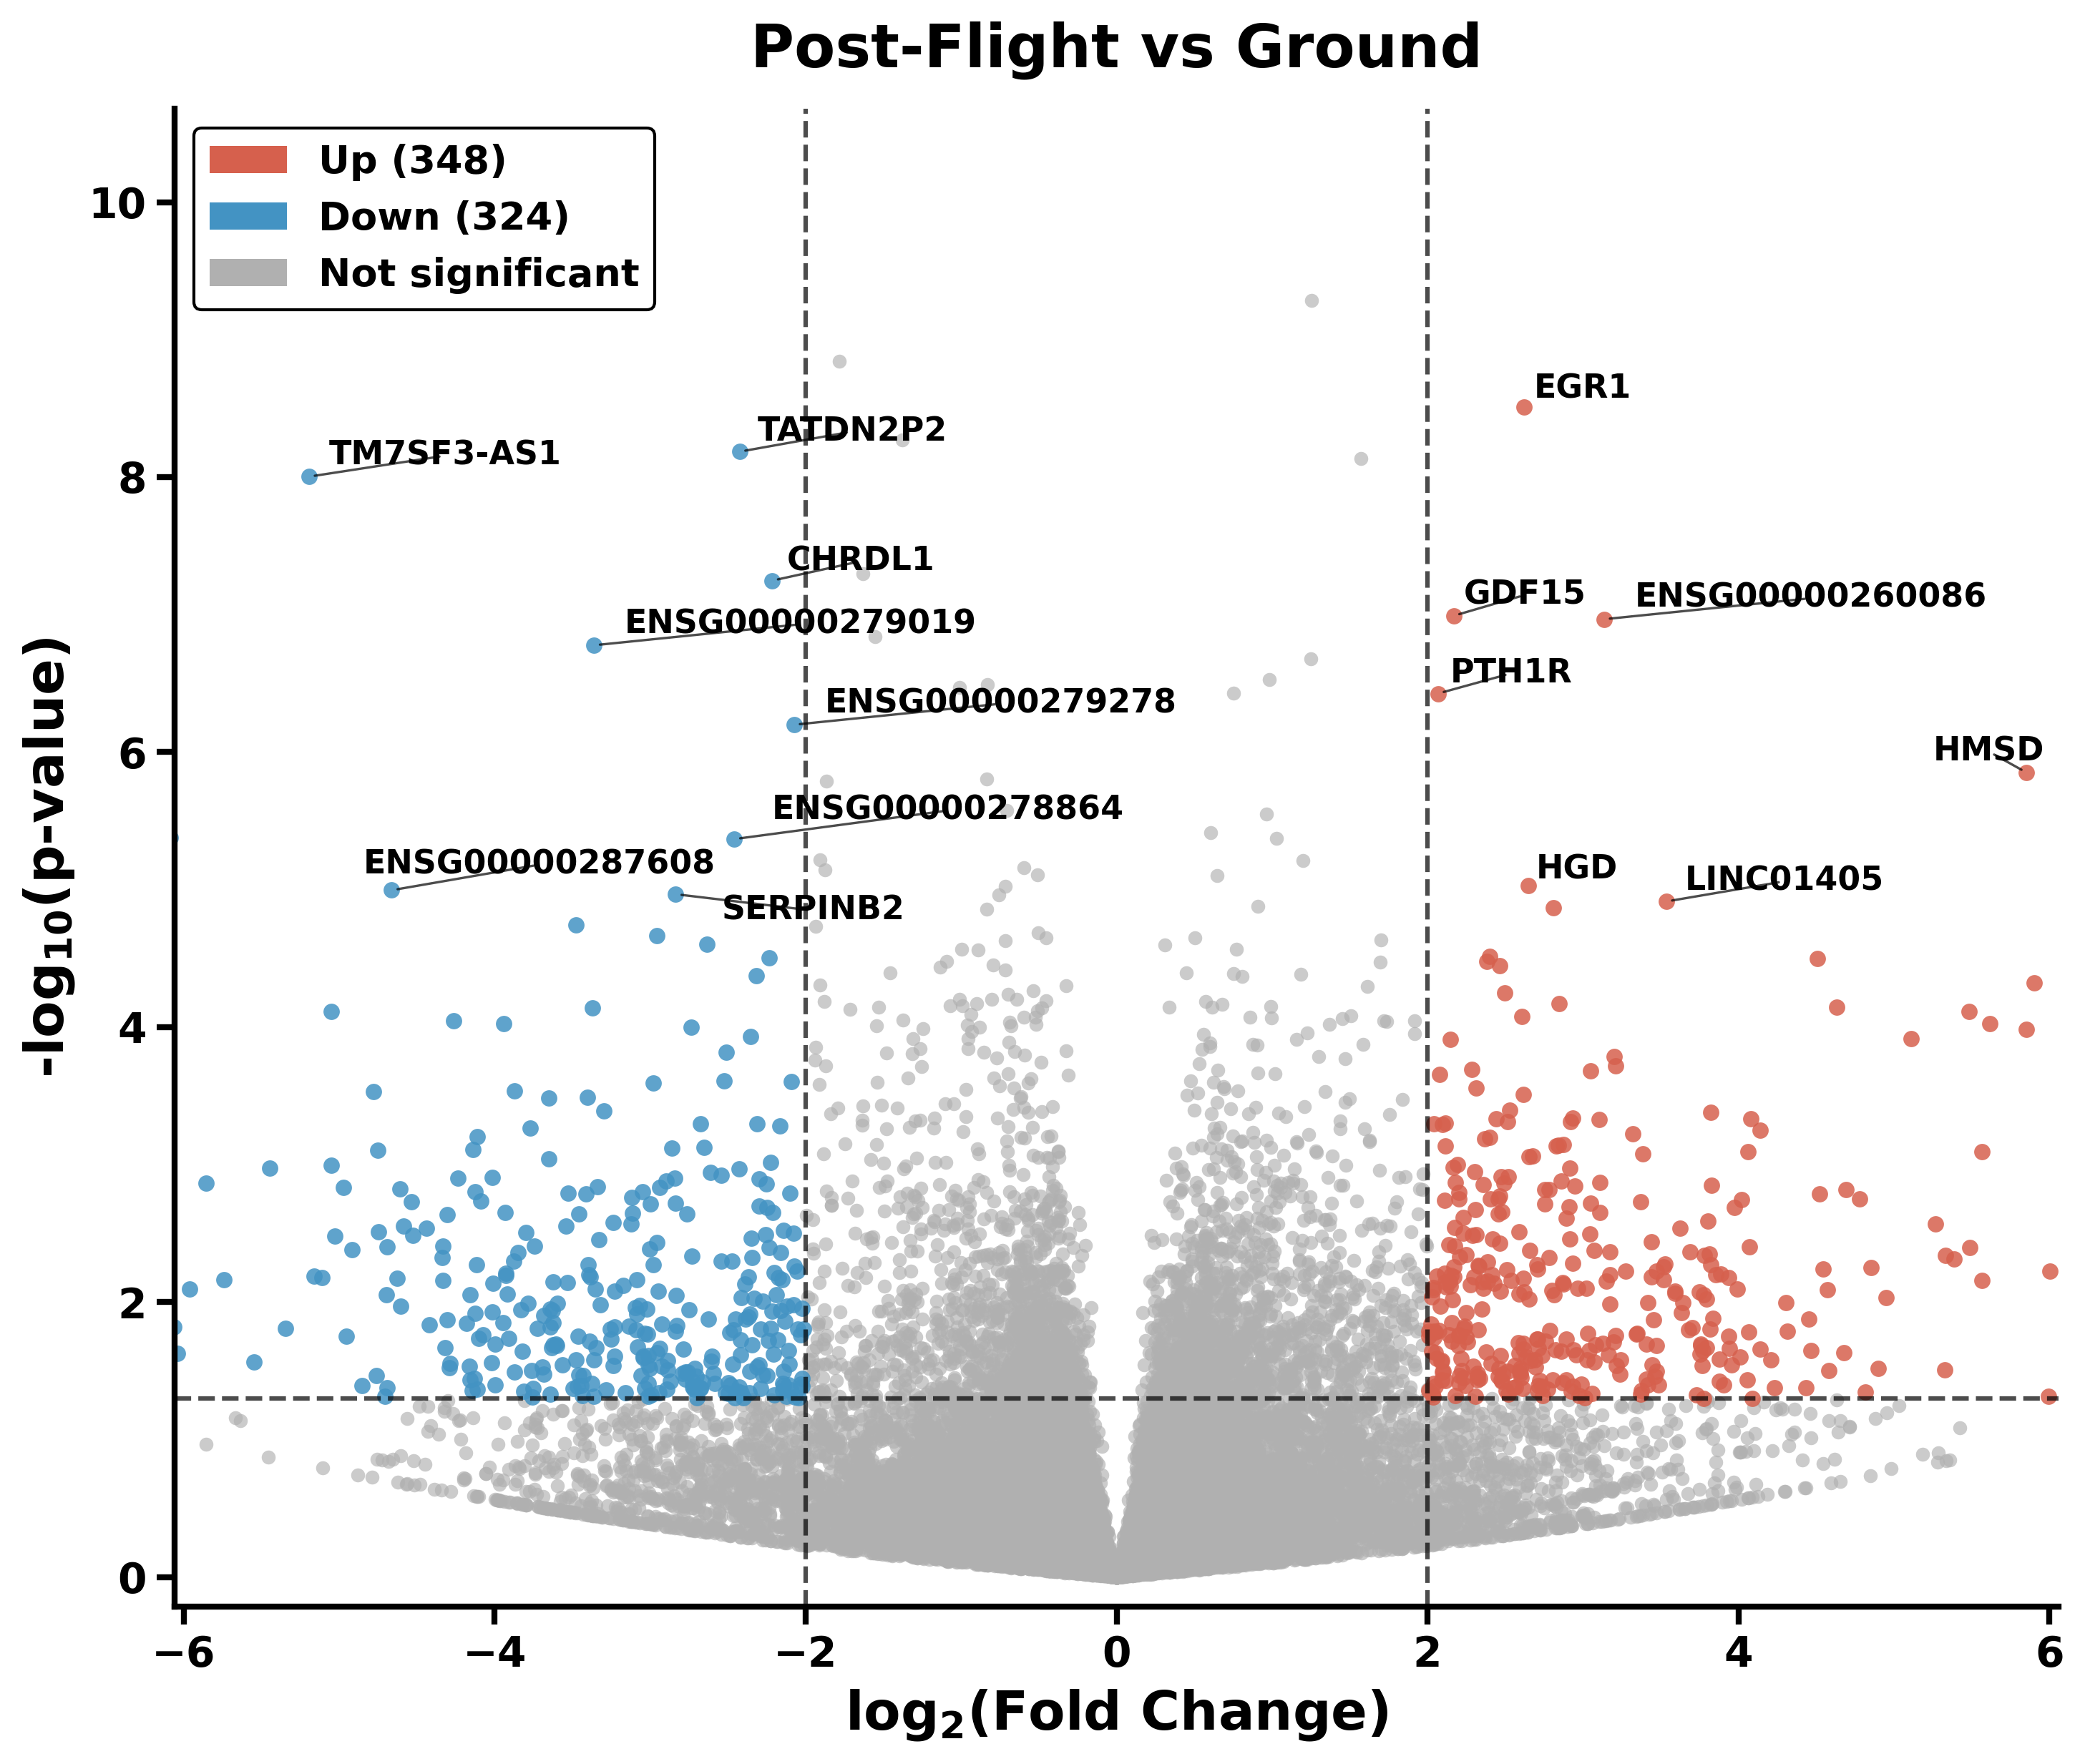

Saved: /mnt/user-data/outputs/volcano_PostFlight_vs_Ground.png (348 up / 324 down / 26935 total genes)


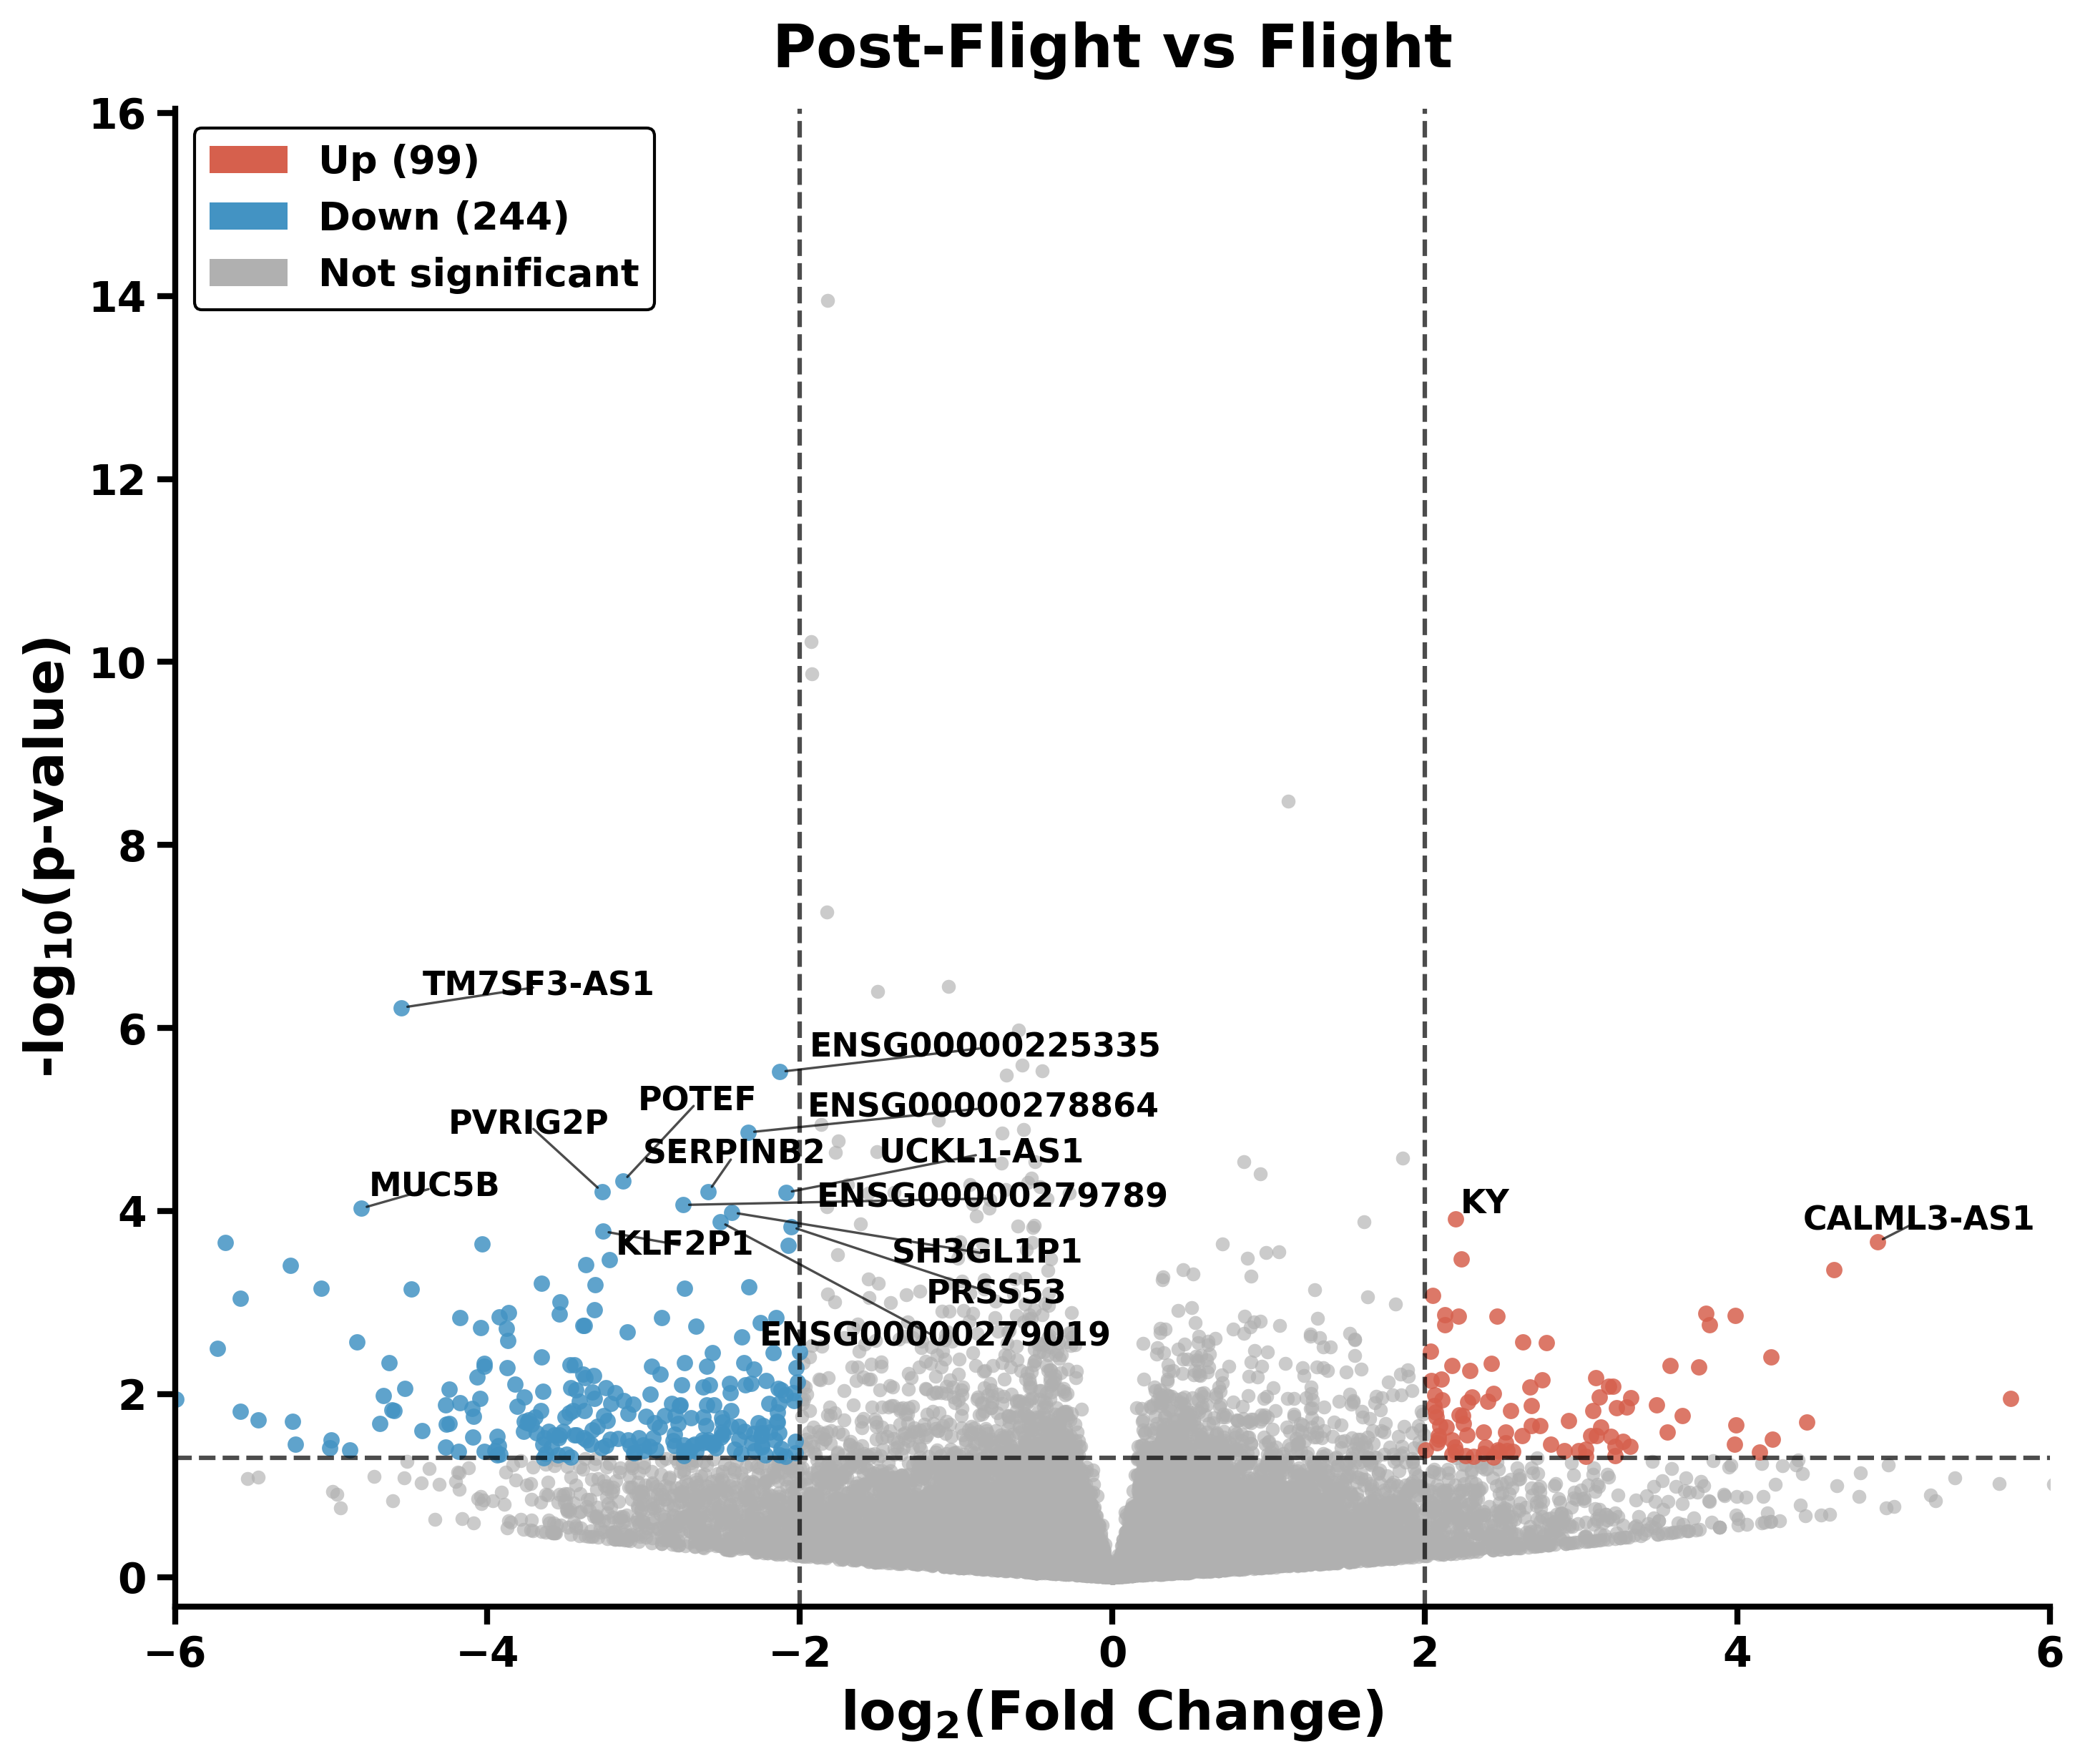

Saved: /mnt/user-data/outputs/volcano_PostFlight_vs_Flight.png (99 up / 244 down / 26935 total genes)


In [7]:
deg_results = {}
for comp in COMPARISONS:
    deg_results[comp["out"]] = make_volcano(
        filepath=os.path.join(INPUT_DIR, comp["file"]),
        lfc_col=comp["lfc_col"],
        pval_col=comp["pval_col"],
        title=comp["title"],
        out_basename=comp["out"],
    )

## 7. Generate the PCA plot

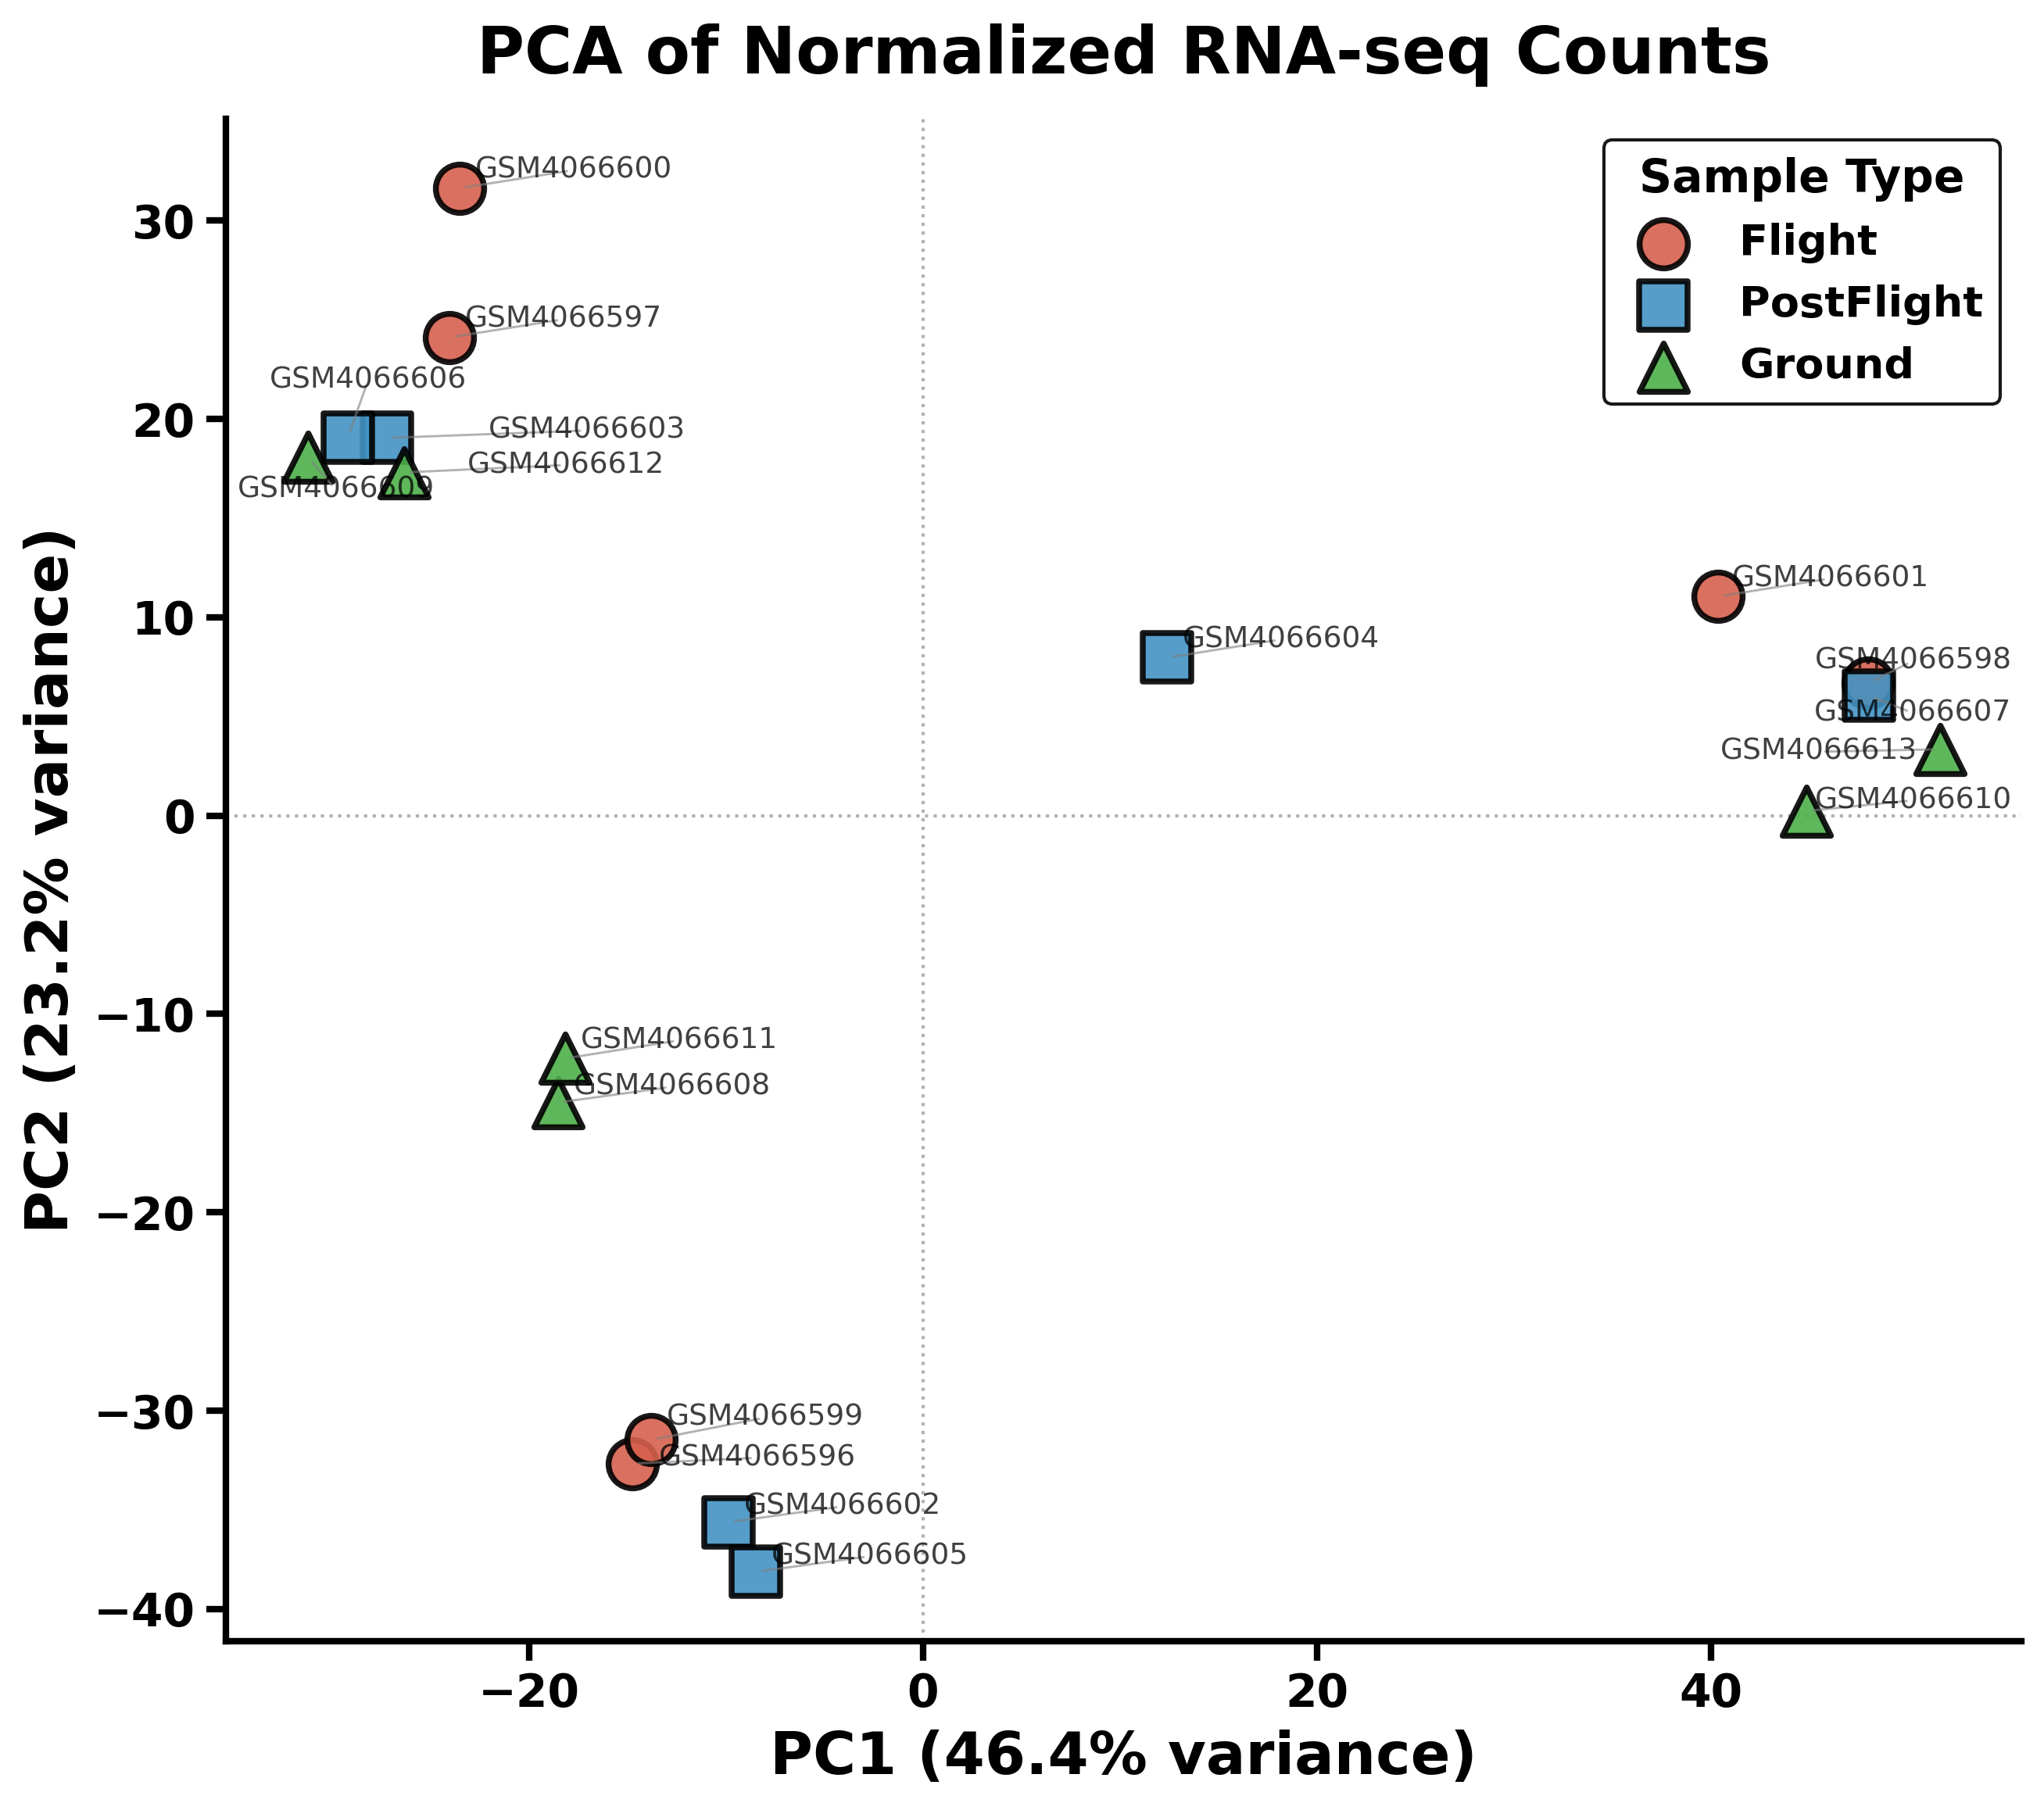

Saved: /mnt/user-data/outputs/PCA_plot.png

All figures generated at 300 DPI (PNG + PDF) in: /mnt/user-data/outputs


In [8]:
pca_scores = make_pca(
    counts_path=os.path.join(INPUT_DIR, COUNTS_FILE),
    metadata_path=os.path.join(INPUT_DIR, METADATA_FILE),
    out_basename="PCA_plot",
)

print("\nAll figures generated at 300 DPI (PNG + PDF) in:", OUTPUT_DIR)